# BEE 4750 — Mini Project

## Part 1

**Part 1.1.** A single closed-form Streeter–Phelps solution does not directly describe the full reach because discharges at 0, 15, and 32 km change concentrations through instantaneous mixing and the sludge bed adds a spatially varying oxygen sink over 20–30 km. Piecewise analytical solutions are possible, but forward Euler handles these changes more directly.

**Part 1.2.** Let $C$, $B$, and $N$ denote DO, CBOD, and NBOD (mg/L). With flow speed $U=6$ km/day,

$$\frac{dC}{dx}=\frac{k_a(C_s-C)-k_cB-k_nN-S_B(x)}{U}, \qquad
\frac{dB}{dx}=-\frac{k_cB}{U}, \qquad
\frac{dN}{dx}=-\frac{k_nN}{U}.$$

For each state variable, use forward Euler: $Y_{i+1}=Y_i+\Delta x \, (dY/dx)_i$.
At each facility, apply $Y_{\mathrm{mixed}}=(Q_rY_r+Q_eY_e)/(Q_r+Q_e)$ and set downstream flow to $Q_r+Q_e$.

**Part 1.3.** Model all three facilities with no treatment.
Plot DO and compare the minimum with the 4 mg/L standard.

Minimum DO: 0.277 mg/L at x = 39.90 km
Required standard: 4.0 mg/L
Meets standard everywhere: False

Step-size check:
dx = 0.100 km: min DO = 0.2697 mg/L at 39.900 km
dx = 0.050 km: min DO = 0.2773 mg/L at 39.900 km
dx = 0.025 km: min DO = 0.2811 mg/L at 39.900 km


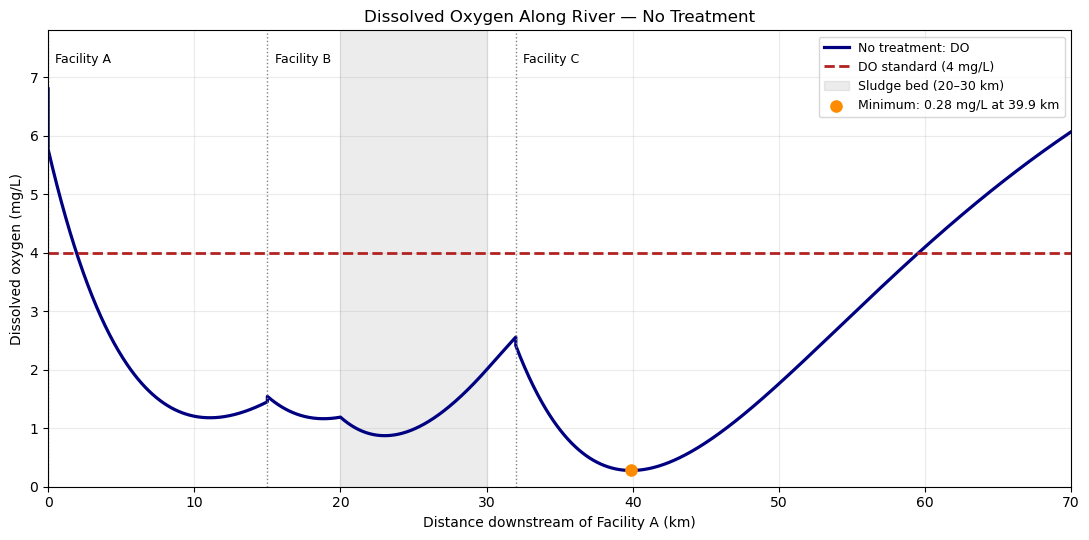

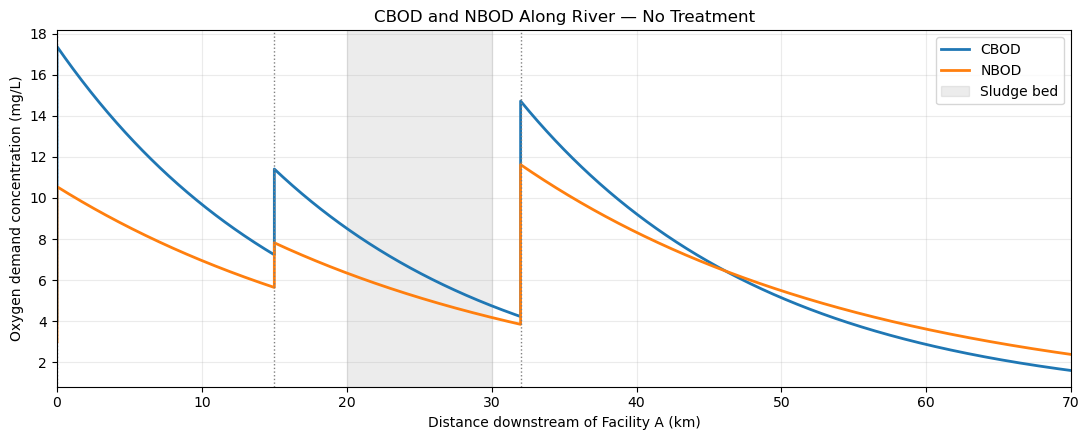

In [1]:
#Part 1: DO, CBOD, and NBOD (no treatment)
import numpy as np
import matplotlib.pyplot as plt

# River parameters: rates [1/day], DO [mg/L], velocity [km/day]
ka, kc, kn = 0.55, 0.35, 0.25
Cs, U = 10.0, 6.0
DO_standard = 4.0

# River immediately upstream of Facility A
river_flow = 80_000.0  # m^3/day
river_DO, river_CBOD, river_NBOD = 6.8, 4.0, 3.0

# Facility information in downstream order: A, B, C
facility_location = np.array([0.0, 15.0, 32.0])  # km
facility_flow = np.array([22_000.0, 10_000.0, 18_000.0])  # m^3/day
facility_DO = np.array([2.0, 2.5, 1.5])  # mg/L
facility_CBOD = np.array([66.0, 54.0, 80.0])  # mg/L
facility_NBOD = np.array([38.0, 30.0, 60.0])  # mg/L


def sludge_demand(x):
    """Oxygen demand of the sludge bed [mg/(L*day)]."""
    if 20.0 <= x <= 30.0:
        return 1.6 * (1.0 - (x - 20.0) / 10.0)
    return 0.0


def simulate_river(dx=0.05, removal=(0.0, 0.0, 0.0)):
    """Forward Euler simulation with instantaneous mixing at A, B, and C."""
    # Require a grid point at every facility and both sludge-bed edges.
    for x_event in [0.0, 15.0, 20.0, 30.0, 32.0, 70.0]:
        if not np.isclose(x_event / dx, round(x_event / dx)):
            raise ValueError("Choose dx so 15, 20, 30, 32, and 70 km lie on the grid.")

    n_steps = int(round(70.0 / dx))
    grid = np.linspace(0.0, 70.0, n_steps + 1)
    facility_at_step = {int(round(loc / dx)): j
                        for j, loc in enumerate(facility_location)}

    # State = [DO, CBOD, NBOD]; start just upstream of Facility A.
    state = np.array([river_DO, river_CBOD, river_NBOD], dtype=float)
    flow = river_flow
    x_values, states = [0.0], [state.copy()]

    for i, x in enumerate(grid):
        # Mix effluent exactly at the facility grid point, before moving on.
        if i in facility_at_step:
            j = facility_at_step[i]
            q = facility_flow[j]
            effluent = np.array([facility_DO[j],
                                 facility_CBOD[j] * (1.0 - removal[j]),
                                 facility_NBOD[j] * (1.0 - removal[j])])
            state = (flow * state + q * effluent) / (flow + q)
            flow += q

            # Duplicate x to show the instantaneous concentration jump.
            x_values.append(x)
            states.append(state.copy())

        if i == n_steps:
            break

        C, B, N = state
        rates = np.array([
            ka * (Cs - C) - kc * B - kn * N - sludge_demand(x),
            -kc * B,
            -kn * N
        ])
        state = state + (dx / U) * rates  # Forward Euler
        x_values.append(grid[i + 1])
        states.append(state.copy())

    return np.array(x_values), np.array(states)


# Part 1.3: no treatment at any facility.
dx = 0.05  # km
x, results = simulate_river(dx=dx)
DO, CBOD, NBOD = results.T
min_index = np.argmin(DO)
x_min, DO_min = x[min_index], DO[min_index]

print(f"Minimum DO: {DO_min:.3f} mg/L at x = {x_min:.2f} km")
print(f"Required standard: {DO_standard:.1f} mg/L")
print(f"Meets standard everywhere: {np.all(DO >= DO_standard)}")

# Step-size check: forward Euler should approach the same answer as dx shrinks.
print("\nStep-size check:")
for test_dx in [0.10, 0.05, 0.025]:
    test_x, test_results = simulate_river(dx=test_dx)
    j = np.argmin(test_results[:, 0])
    print(f"dx = {test_dx:.3f} km: min DO = {test_results[j, 0]:.4f} "
          f"mg/L at {test_x[j]:.3f} km")

# Required plot: DO along the river, including the 4 mg/L standard.
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(x, DO, lw=2.3, color='navy', label='No treatment: DO')
ax.axhline(DO_standard, ls='--', lw=2, color='firebrick', label='DO standard (4 mg/L)')
ax.axvspan(20, 30, alpha=0.15, color='gray', label='Sludge bed (20–30 km)')
ax.scatter(x_min, DO_min, color='darkorange', s=65, zorder=4,
           label=f'Minimum: {DO_min:.2f} mg/L at {x_min:.1f} km')

for name, location in zip('ABC', facility_location):
    ax.axvline(location, lw=1, ls=':', color='0.5')
    ax.text(location + 0.5, 7.25, f'Facility {name}', fontsize=9)

ax.set(xlabel='Distance downstream of Facility A (km)',
       ylabel='Dissolved oxygen (mg/L)',
       title='Dissolved Oxygen Along River — No Treatment',
       xlim=(0, 70), ylim=(0, 7.8))
ax.grid(alpha=0.25)
ax.legend(loc='upper right', fontsize=9)
fig.tight_layout()
plt.show()

# Additional plot: concentration profiles of the two oxygen demands.
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(x, CBOD, label='CBOD', lw=2)
ax.plot(x, NBOD, label='NBOD', lw=2)
ax.axvspan(20, 30, alpha=0.15, color='gray', label='Sludge bed')
for location in facility_location:
    ax.axvline(location, lw=1, ls=':', color='0.5')
ax.set(xlabel='Distance downstream of Facility A (km)',
       ylabel='Oxygen demand concentration (mg/L)',
       title='CBOD and NBOD Along River — No Treatment',
       xlim=(0, 70))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


## Comments:

Since $\Delta x=0.05$ km, the minimum DO is approximately 0.277 mg/L at 39.90 km, below the required 4 mg/L. This minimum occurs downstream of Facility C (32 km), where newly added CBOD and NBOD continue consuming oxygen until reaeration balances the remaining demand.

## Part 2

Compare successively halved spatial step sizes against a very fine no-treatment reference. Calculate absolute errors, coarse-to-fine improvement ratios, and the log–log convergence slope. The expected order for forward Euler is $p=1$.

Reference: dx = 0.0001 km; minimum DO = 0.284899 mg/L at x = 39.896 km

Convergence study (no treatment):
   dx (km)    Min DO (mg/L)     Error (mg/L)    Improvement
   0.20000         0.254453         0.030446            ---
   0.10000         0.269732         0.015167          2.007
   0.05000         0.277340         0.007559          2.007
   0.02500         0.281132         0.003767          2.006
   0.01250         0.283024         0.001875          2.009
   0.00625         0.283969         0.000930          2.016

Observed log-log slope = 1.006 (Forward Euler theory: 1.000)
Selected dx = 0.050 km; absolute error = 0.007559 mg/L


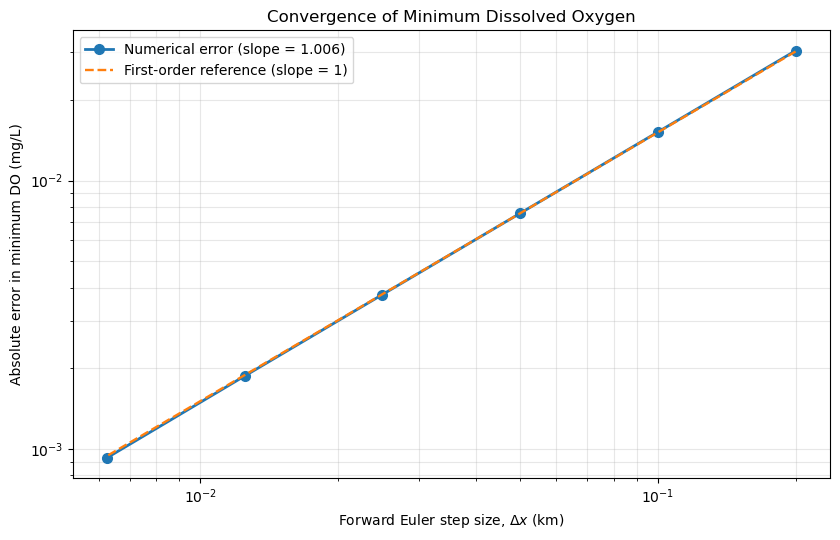

In [3]:
# Part 2: Convergence study for minimum DO (no treatment)

# Forward Euler grid (0.1 metre spacing).
reference_dx = 0.0001  # km
x_ref, result_ref = simulate_river(dx=reference_dx)
ref_index = np.argmin(result_ref[:, 0])
ref_min_DO = result_ref[ref_index, 0]
ref_min_x = x_ref[ref_index]

# Successively halved steps
# Each grid includes A, B, C, 20 km, and 30 km.
step_sizes = np.array([0.20, 0.10, 0.05, 0.025, 0.0125, 0.00625])
minimum_DO = np.empty(len(step_sizes))
minimum_x = np.empty(len(step_sizes))

for i, step in enumerate(step_sizes):
    x_test, result_test = simulate_river(dx=step)
    minimum_index = np.argmin(result_test[:, 0])
    minimum_DO[i] = result_test[minimum_index, 0]
    minimum_x[i] = x_test[minimum_index]

# Absolute error compared with the reference and coarse-to-fine improvement.
errors = np.abs(minimum_DO - ref_min_DO)
improvement = np.full(len(step_sizes), np.nan)
improvement[1:] = errors[:-1] / errors[1:]

# Fit log(error) = constant + p*log(step size); p is the observed order.
slope, intercept = np.polyfit(np.log10(step_sizes), np.log10(errors), 1)

print(f"Reference: dx = {reference_dx:.4f} km; "
      f"minimum DO = {ref_min_DO:.6f} mg/L at x = {ref_min_x:.3f} km")
print("\nConvergence study (no treatment):")
print(f"{'dx (km)':>10} {'Min DO (mg/L)':>16} {'Error (mg/L)':>16} {'Improvement':>14}")
for i, step in enumerate(step_sizes):
    ratio = "---" if i == 0 else f"{improvement[i]:.3f}"
    print(f"{step:10.5f} {minimum_DO[i]:16.6f} {errors[i]:16.6f} {ratio:>14}")

print(f"\nObserved log-log slope = {slope:.3f} (Forward Euler theory: 1.000)")
recommended_dx = 0.05
recommended_index = np.flatnonzero(np.isclose(step_sizes, recommended_dx))[0]
print(f"Selected dx = {recommended_dx:.3f} km; "
      f"absolute error = {errors[recommended_index]:.6f} mg/L")

# Error vs. step size on log-log axes.
fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.loglog(step_sizes, errors, 'o-', linewidth=2, markersize=7,
          label=f'Numerical error (slope = {slope:.3f})')
ax.loglog(step_sizes, errors[2] * (step_sizes / step_sizes[2]), '--',
          linewidth=1.7, label='First-order reference (slope = 1)')
ax.set(xlabel='Forward Euler step size, $\\Delta x$ (km)',
       ylabel='Absolute error in minimum DO (mg/L)',
       title='Convergence of Minimum Dissolved Oxygen')
ax.grid(True, which='both', alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()


### Comments:

When $\Delta x$ is halved, the global discretization error should be approximately halved which improved the ratio of about 2 and a log–log slope of about 1. The 0.05 km grid retains the exact mixing and sludge boundaries and gives an error below 0.008 mg/L in the predicted minimum DO.

## Part 3

Evaluate the four treatment plans at the Part 2 selected step size of 0.05 km. Compare minimum DO, location, and 4 mg/L compliance; then remove the sludge oxygen-demand term for dredging.


PART 3.1: Treatment plans (original sludge bed)
Plan       Annual cost    Min DO (mg/L)     x (km)      Margin
1      $     1,165,000            3.825      39.50      -0.175
2      $     1,380,000            4.261      39.95       0.261
3      $     1,540,000            4.592      24.05       0.592
4      $     1,895,000            4.282      40.20       0.282


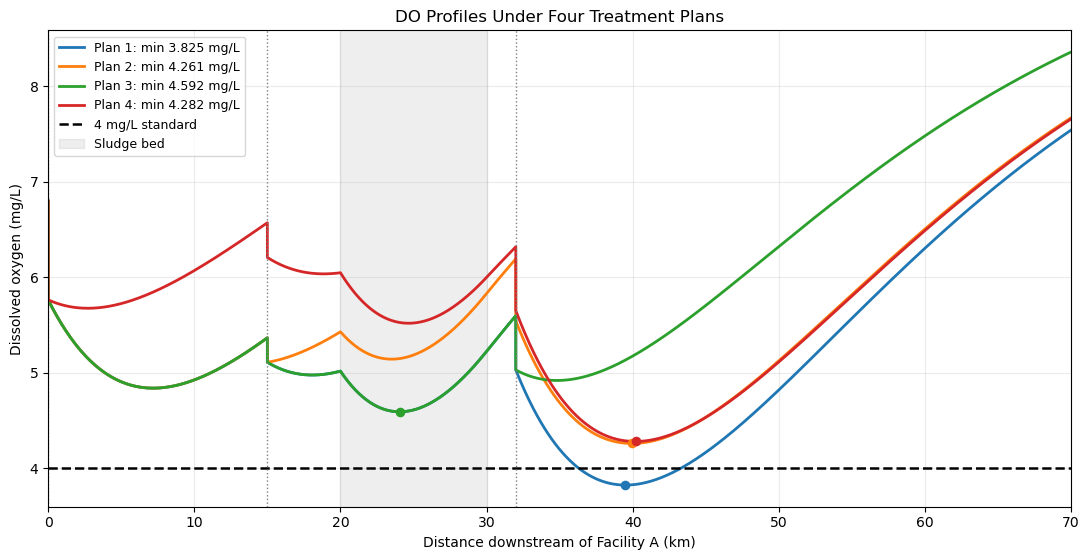


PART 3.2: Comparing Plans 3 and 4
Plan 3 margin: 0.592 mg/L
Plan 4 margin: 0.282 mg/L
Plan 4 costs $355,000/yr more than Plan 3.

PART 3.3: Dredging with no treatment
Original minimum DO: 0.277340 mg/L at 39.90 km
Dredged minimum DO:  0.530661 mg/L at 40.40 km
Minimum DO improvement: 0.253320 mg/L
Original 4 mg/L shortfall: 3.722660 mg/L
Fraction of original shortfall eliminated: 6.80%

Treatment effectiveness before and after dredging:
Plan       With sludge (mg/L)    After dredging (mg/L)
1                       3.825                    4.083
2                       4.261                    4.509
3                       4.592                    4.840
4                       4.282                    4.525


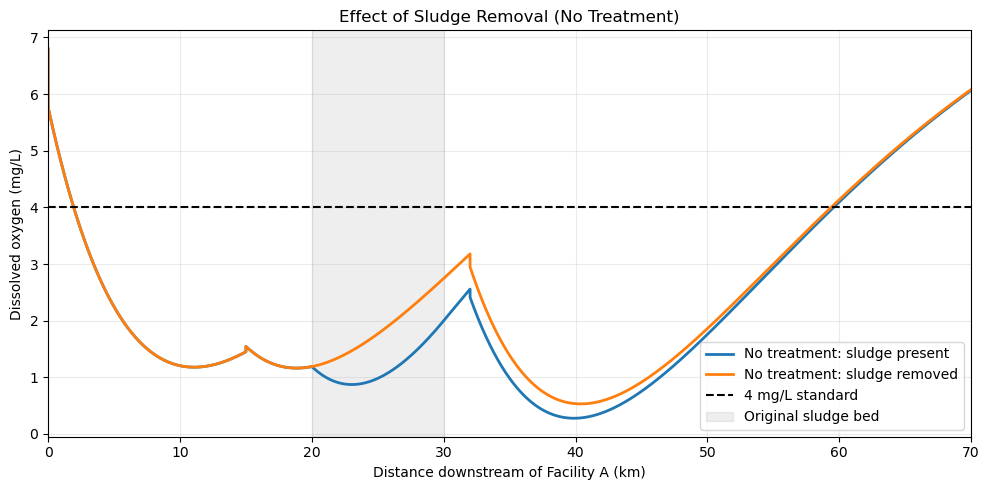

In [7]:
# Part 3: Treatment plans and sludge dredging

# Treatment fractions at facilities A, B, C (Table 3)
plan_removal = [
    (0.65, 0.35, 0.35),  # Plan 1
    (0.65, 0.65, 0.35),  # Plan 2
    (0.65, 0.35, 0.65),  # Plan 3
    (0.85, 0.35, 0.35),  # Plan 4
]
plan_cost = [1_165_000, 1_380_000, 1_540_000, 1_895_000]

# Extension of Part 1 simulation with an option to remove the sludge bed.
def simulate_scenario(dx=0.05, removal=(0.0, 0.0, 0.0), dredged=False):
    for event in [0.0, 15.0, 20.0, 30.0, 32.0, 70.0]:
        if not np.isclose(event / dx, round(event / dx)):
            raise ValueError('Choose dx that puts all facilities and sludge edges on the grid.')

    n_steps = int(round(70.0 / dx))
    grid = np.linspace(0.0, 70.0, n_steps + 1)
    facility_steps = {int(round(loc / dx)): j
                      for j, loc in enumerate(facility_location)}
    state = np.array([river_DO, river_CBOD, river_NBOD], dtype=float)
    flow = river_flow
    distances, concentrations = [0.0], [state.copy()]

    for i, x in enumerate(grid):
        if i in facility_steps:
            j = facility_steps[i]
            q = facility_flow[j]
            effluent = np.array([facility_DO[j],
                                 facility_CBOD[j] * (1.0 - removal[j]),
                                 facility_NBOD[j] * (1.0 - removal[j])])
            state = (flow * state + q * effluent) / (flow + q)
            flow += q
            distances.append(x)
            concentrations.append(state.copy())

        if i == n_steps:
            break

        C, B, N = state
        bed_demand = 0.0 if dredged else sludge_demand(x)
        rates = np.array([ka * (Cs - C) - kc * B - kn * N - bed_demand,
                          -kc * B, -kn * N])
        state = state + (dx / U) * rates
        distances.append(grid[i + 1])
        concentrations.append(state.copy())

    return np.array(distances), np.array(concentrations)


def summarize_scenario(removal, dredged=False, dx=0.05):
    x, states = simulate_scenario(dx=dx, removal=removal, dredged=dredged)
    i = np.argmin(states[:, 0])
    return x, states, float(x[i]), float(states[i, 0])


# Part 3.1: Simulate all four plans with the original sludge bed.
plan_results = []

print('PART 3.1: Treatment plans (original sludge bed)')
print(f"{'Plan':<7}{'Annual cost':>15}{'Min DO (mg/L)':>17}{'x (km)':>11}{'Margin':>12}")

for j, removal in enumerate(plan_removal):
    x_j, state_j, x_min_j, do_min_j = summarize_scenario(removal)
    plan_results.append((x_j, state_j, x_min_j, do_min_j))

    print(f'{j+1:<7}${plan_cost[j]:>14,}{do_min_j:>17.3f}'
          f'{x_min_j:>11.2f}{do_min_j-DO_standard:>12.3f}')

fig, ax = plt.subplots(figsize=(11, 5.7))

for j, (x_j, state_j, x_min_j, do_min_j) in enumerate(plan_results):
    (line,) = ax.plot(x_j, state_j[:, 0], lw=2,
                      label=f'Plan {j+1}: min {do_min_j:.3f} mg/L')
    ax.scatter(x_min_j, do_min_j, color=line.get_color(), s=35, zorder=3)

ax.axhline(DO_standard, ls='--', color='black', lw=1.8,
           label='4 mg/L standard')
ax.axvspan(20, 30, color='gray', alpha=0.13, label='Sludge bed')

for location in facility_location:
    ax.axvline(location, ls=':', color='gray', lw=1)

ax.set(xlim=(0, 70), xlabel='Distance downstream of Facility A (km)',
       ylabel='Dissolved oxygen (mg/L)',
       title='DO Profiles Under Four Treatment Plans')
ax.grid(alpha=0.25)
ax.legend(loc='best', fontsize=9)
fig.tight_layout()
plt.show()


# Part 3.2: Compare the margins and expenses of Plans 3 and 4.
margin3 = plan_results[2][3] - DO_standard
margin4 = plan_results[3][3] - DO_standard

print('\nPART 3.2: Comparing Plans 3 and 4')
print(f'Plan 3 margin: {margin3:.3f} mg/L')
print(f'Plan 4 margin: {margin4:.3f} mg/L')
print(f'Plan 4 costs ${plan_cost[3]-plan_cost[2]:,}/yr more than Plan 3.')


# Part 3.3: Remove benthic oxygen demand (dredged=True).
_, _, original_x, original_min = summarize_scenario((0, 0, 0), dredged=False)

untreated_dredged_x, untreated_dredged_state, dredged_x, dredged_min = \
    summarize_scenario((0, 0, 0), dredged=True)

improvement = dredged_min - original_min
original_shortfall = DO_standard - original_min
fraction_explained = 100 * improvement / original_shortfall

print('\nPART 3.3: Dredging with no treatment')
print(f'Original minimum DO: {original_min:.6f} mg/L at {original_x:.2f} km')
print(f'Dredged minimum DO:  {dredged_min:.6f} mg/L at {dredged_x:.2f} km')
print(f'Minimum DO improvement: {improvement:.6f} mg/L')
print(f'Original 4 mg/L shortfall: {original_shortfall:.6f} mg/L')
print(f'Fraction of original shortfall eliminated: {fraction_explained:.2f}%')

print('\nTreatment effectiveness before and after dredging:')
print(f"{'Plan':<7}{'With sludge (mg/L)':>22}{'After dredging (mg/L)':>25}")

for j, removal in enumerate(plan_removal):
    _, _, _, new_min = summarize_scenario(removal, dredged=True)
    old_min = plan_results[j][3]

    print(f'{j+1:<7}{old_min:>22.3f}{new_min:>25.3f}')


# Optional visualization: untreated DO before vs. after sludge removal.
untreated_x, untreated_state, _, _ = summarize_scenario((0, 0, 0))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(untreated_x, untreated_state[:, 0], lw=2,
        label='No treatment: sludge present')
ax.plot(untreated_dredged_x, untreated_dredged_state[:, 0], lw=2,
        label='No treatment: sludge removed')
ax.axhline(DO_standard, ls='--', color='black',
           label='4 mg/L standard')
ax.axvspan(20, 30, color='gray', alpha=0.13,
           label='Original sludge bed')

ax.set(xlim=(0, 70), xlabel='Distance downstream of Facility A (km)',
       ylabel='Dissolved oxygen (mg/L)',
       title='Effect of Sludge Removal (No Treatment)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()



### Comments:

With the sludge present, Plans 2, 3, and 4 pass the 4 mg/L standard. However, Plan 1 fails. Plan 3 has a higher minimum DO than Plan 4 because treatment at downstream Facility C prevents recent oxygen-demanding loads from depressing DO near 40 km.


# Part 4

**4.1:** Sample Facility C's effluent three independent distributions; estimate violation probability with Wilson 95% confidence intervals.

**4.2:** Hold the random sample fixed while varying step size, then hold the step size fixed while changing the Monte Carlo sample size.

**4.3:** Distinguish confidence-interval sampling uncertainty from Euler discretization error.

**4.4:** Screen 64 treatment combinations at mean conditions, then simulate the survivors in ascending cost order.

**Monte Carlo Paramters:** 20,000 random days, seed 4750, Euler spacing 0.05 km. Facility C's DO is sampled from a normal distribution truncated at zero.

PART 4.1: Monte Carlo, n=20,000, seed=4750, dx=0.05 km
Scenario                 Events   P(violation)           95% Wilson CI
Plan 2                     4199       20.995%   [20.436%, 21.565%]
Plan 3                        0        0.000%   [ 0.000%,  0.019%]
Plan 4                     3903       19.515%   [18.972%, 20.070%]
Plan 1 + dredging          8054       40.270%   [39.592%, 40.952%]


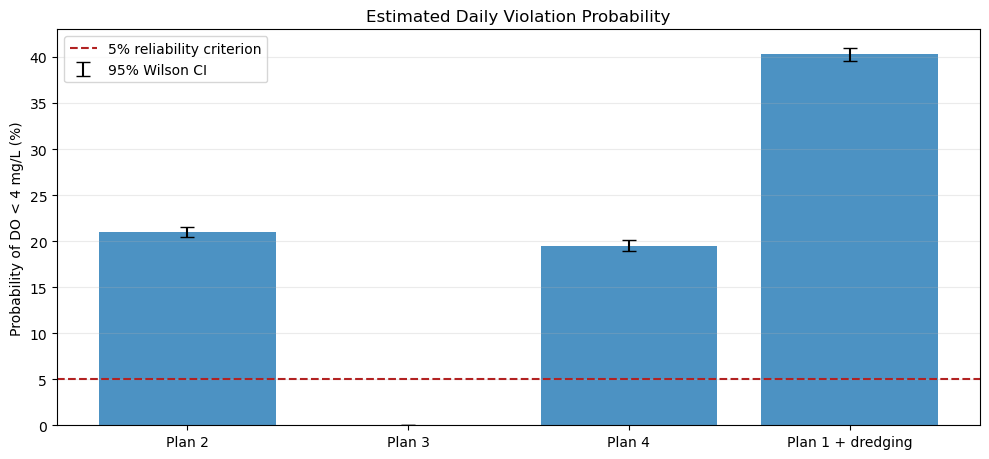


PART 4.2A: Hold n and seed fixed; vary dx for Plan 2
   dx [km]    violations        p_hat              95% Wilson CI
   0.20000         4,511      22.555%   [21.981%, 23.139%]
   0.10000         4,287      21.435%   [20.872%, 22.009%]
   0.05000         4,199      20.995%   [20.436%, 21.565%]
   0.02500         4,165      20.825%   [20.268%, 21.393%]
   0.01250         4,135      20.675%   [20.119%, 21.242%]
   0.00625         4,124      20.620%   [20.065%, 21.186%]

PART 4.2B: Hold dx and seed fixed; vary n for Plan 2
         n    violations        p_hat        MC SE              95% Wilson CI
       500           127      25.400%       1.947%   [21.782%, 29.393%]
     1,000           224      22.400%       1.318%   [19.924%, 25.087%]
     2,000           435      21.750%       0.922%   [19.997%, 23.611%]
     5,000         1,049      20.980%       0.576%   [19.874%, 22.131%]
    10,000         2,094      20.940%       0.407%   [20.154%, 21.749%]
    20,000         4,199      20.99

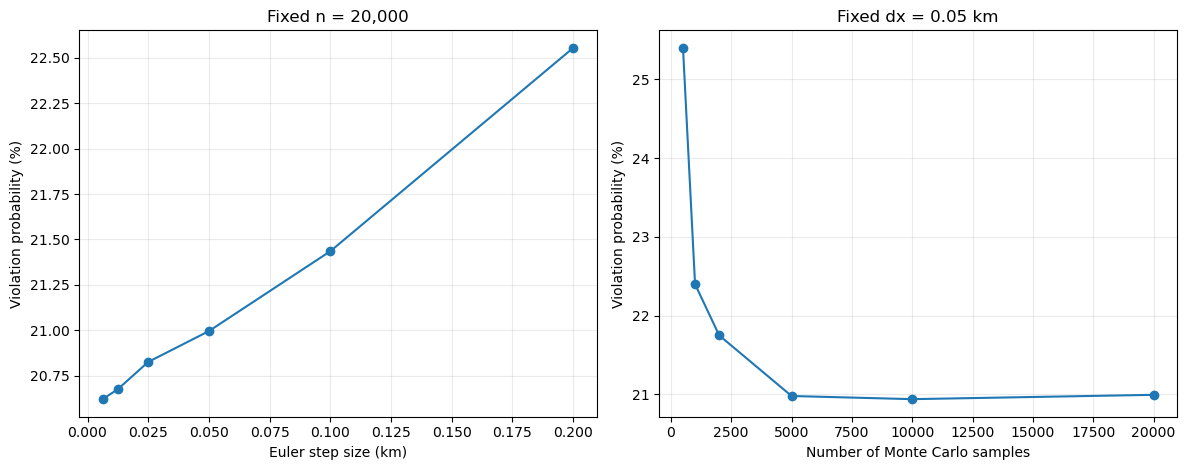


PART 4.4: 19 of 64 plans pass the mean-DO screen
Sampling screened plans in order of increasing annual cost:
$1,380,000 | ('Secondary', 'Secondary', 'Primary')       mean-min 4.261 | k= 4199 | p=20.995% | 95% CI [20.436%, 21.565%]
$1,540,000 | ('Secondary', 'Primary', 'Secondary')       mean-min 4.592 | k=    0 | p= 0.000% | 95% CI [0.000%, 0.019%]

Plans evaluated by Monte Carlo in cost order: 2
Cheapest plan with estimated p < 5%: ('Secondary', 'Primary', 'Secondary')
Annual cost: $1,540,000; mean minimum DO = 4.592 mg/L
Estimated violation probability = 0.000% [0.000%, 0.019%]


In [6]:
# Part 4: Monte Carlo reliability and plan selection

from itertools import product
from math import sqrt
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt

SEED = 4750
N_MC = 20_000
DX = 0.05             # selected in Part 2 [km]
DO_LIMIT = 4.0         # regulatory standard [mg/L]


def draw_facility_c(n, seed=SEED):
    """Independent Facility C effluent values; DO is normal truncated at zero."""
    rng = np.random.default_rng(seed)
    do_c = rng.normal(1.5, 0.5, size=n)
    # Rejection sampling gives a normal distribution conditional on DO >= 0.
    mask = do_c < 0
    while np.any(mask):
        do_c[mask] = rng.normal(1.5, 0.5, size=mask.sum())
        mask = do_c < 0
    cbod_c = rng.normal(80.0, 12.0, size=n)
    nbod_c = rng.normal(60.0, 9.0, size=n)
    return np.column_stack((do_c, cbod_c, nbod_c))


def monte_carlo_min_do(removal, c_samples, dx=DX, dredged=False):
    """Vectorized Euler simulation: returns one river-wide min DO per sample."""
    n = len(c_samples)
    num_steps = int(round(70.0 / dx))
    if any(not np.isclose(a / dx, round(a / dx))
           for a in (15., 20., 30., 32., 70.)):
        raise ValueError('Step size must align with all facilities and sludge edges.')

    # Arrays hold the three concentrations for every simulated day.
    C = np.full(n, river_DO, dtype=float)
    B = np.full(n, river_CBOD, dtype=float)
    N = np.full(n, river_NBOD, dtype=float)
    low = np.full(n, np.inf)
    flow = float(river_flow)
    event = {int(round(pos / dx)): j
             for j, pos in enumerate(facility_location)}
    dt = dx / U

    for i in range(num_steps + 1):
        x = i * dx
        if i in event:
            j = event[i]
            q = float(facility_flow[j])
            if j < 2:
                # A and B are fixed on every Monte Carlo day.
                e_do = facility_DO[j]
                e_b = facility_CBOD[j] * (1 - removal[j])
                e_n = facility_NBOD[j] * (1 - removal[j])
            else:
                # All three variables at C change in every sample.
                e_do = c_samples[:, 0]
                e_b = c_samples[:, 1] * (1 - removal[j])
                e_n = c_samples[:, 2] * (1 - removal[j])

            C = (flow * C + q * e_do) / (flow + q)
            B = (flow * B + q * e_b) / (flow + q)
            N = (flow * N + q * e_n) / (flow + q)
            flow += q

        np.minimum(low, C, out=low)  # also check DO immediately after mixing
        if i == num_steps:
            break

        SB = 0.0 if dredged else sludge_demand(x)
        C += dt * (ka * (Cs - C) - kc * B - kn * N - SB)
        B *= (1.0 - dt * kc)
        N *= (1.0 - dt * kn)

    return low


def wilson_interval(violations, n, z=1.959963984540054):
    """95% binomial Wilson confidence interval; valid for zero violations."""
    phat = violations / n
    denom = 1.0 + z*z/n
    mid = (phat + z*z/(2*n)) / denom
    half = z * sqrt(phat*(1-phat)/n + z*z/(4*n*n)) / denom
    return max(0., mid - half), min(1., mid + half)


def mc_summary(minima):
    bad = minima < DO_LIMIT
    count = int(bad.sum())
    p = count / len(bad)
    lo, hi = wilson_interval(count, len(bad))
    se = sqrt(p * (1-p) / len(bad))
    return count, p, se, lo, hi


# Draw a single common set of days: reuse across plans and resolutions.
c_samples = draw_facility_c(N_MC, seed=SEED)


# Part 4.1: Reliability of 2, 3, 4 and Plan 1 after dredging

scenario_41 = [
    ('Plan 2', plan_removal[1], False),
    ('Plan 3', plan_removal[2], False),
    ('Plan 4', plan_removal[3], False),
    ('Plan 1 + dredging', plan_removal[0], True),
]

print(f'PART 4.1: Monte Carlo, n={N_MC:,}, seed={SEED}, dx={DX} km')
print(f"{'Scenario':<22}{'Events':>9}{'P(violation)':>15}{'95% Wilson CI':>24}")
part41_results = []
for label, removal, dredged in scenario_41:
    minima = monte_carlo_min_do(removal, c_samples, dx=DX, dredged=dredged)
    k, p, se, lo, hi = mc_summary(minima)
    part41_results.append((label, k, p, se, lo, hi))
    print(f'{label:<22}{k:>9}{p:>14.3%}   [{lo:>7.3%}, {hi:>7.3%}]')

# Plot estimated violation probabilities and 95% CIs.
labels = [r[0] for r in part41_results]
probs = np.array([r[2] for r in part41_results])
lowers = np.array([r[4] for r in part41_results])
uppers = np.array([r[5] for r in part41_results])
fig, ax = plt.subplots(figsize=(10, 4.7))
xx = np.arange(len(labels))
ax.bar(xx, 100*probs, alpha=0.8)
ax.errorbar(xx, 100*probs,
            yerr=[100*(probs-lowers), 100*(uppers-probs)],
            fmt='none', capsize=5, color='black', label='95% Wilson CI')
ax.axhline(5, ls='--', color='firebrick', label='5% reliability criterion')
ax.set_xticks(xx, labels)
ax.set(ylabel='Probability of DO < 4 mg/L (%)',
       title='Estimated Daily Violation Probability')
ax.grid(axis='y', alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


# Part 4.2: Separate spatial error from Monte Carlo error

plan2 = plan_removal[1]
dx_tests = [0.20, 0.10, 0.05, 0.025, 0.0125, 0.00625]

print('\nPART 4.2A: Hold n and seed fixed; vary dx for Plan 2')
print(f"{'dx [km]':>10}{'violations':>14}{'p_hat':>13}{'95% Wilson CI':>27}")
step_results = []
for h in dx_tests:
    minima = monte_carlo_min_do(plan2, c_samples, dx=h)
    k, p, se, lo, hi = mc_summary(minima)
    step_results.append((h, k, p, se, lo, hi))
    print(f'{h:10.5f}{k:14,d}{p:13.3%}   [{lo:.3%}, {hi:.3%}]')

# One fixed simulation gives nested-prefix experiments with different n.
plan2_flags = monte_carlo_min_do(plan2, c_samples, dx=DX) < DO_LIMIT
n_tests = [500, 1000, 2000, 5000, 10000, N_MC]
print('\nPART 4.2B: Hold dx and seed fixed; vary n for Plan 2')
print(f"{'n':>10}{'violations':>14}{'p_hat':>13}{'MC SE':>13}{'95% Wilson CI':>27}")
size_results = []
for n in n_tests:
    k = int(np.count_nonzero(plan2_flags[:n]))
    p = k / n
    se = sqrt(p*(1-p)/n)
    lo, hi = wilson_interval(k, n)
    size_results.append((n, k, p, se, lo, hi))
    print(f'{n:10,d}{k:14,d}{p:13.3%}{se:13.3%}   [{lo:.3%}, {hi:.3%}]')

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot([r[0] for r in step_results],
             [100*r[2] for r in step_results], 'o-')
axes[0].set(xlabel='Euler step size (km)', ylabel='Violation probability (%)',
            title=f'Fixed n = {N_MC:,}')
axes[1].plot([r[0] for r in size_results],
             [100*r[2] for r in size_results], 'o-')
axes[1].set(xlabel='Number of Monte Carlo samples',
            ylabel='Violation probability (%)', title=f'Fixed dx = {DX} km')
for ax in axes:
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()



# Part 4.4: 64 possible plans; deterministic mean screen first

removal_levels = (0., 0.35, 0.65, 0.85)
level_names = ('None', 'Primary', 'Secondary', 'Tertiary')
# One row per facility, columns: none / primary / secondary / tertiary [$1,000/year]
cost_k = np.array([[0, 310, 720, 1450],
                   [0, 180, 395, 810],
                   [0, 265, 640, 1980]])

all_combinations = []
for level_indices in product(range(4), repeat=3):
    removal = tuple(removal_levels[i] for i in level_indices)
    cost = 1000 * sum(cost_k[j, level_indices[j]] for j in range(3))
    _, state = simulate_scenario(dx=DX, removal=removal, dredged=False)
    deterministic_min = float(state[:, 0].min())
    all_combinations.append((cost, level_indices, removal, deterministic_min))

# Screen based on deterministic DO with Facility C at its specified mean.
screened = sorted((v for v in all_combinations if v[3] >= DO_LIMIT),
                  key=lambda v: (v[0], v[1]))
print(f'\nPART 4.4: {len(screened)} of {len(all_combinations)} plans pass the mean-DO screen')
print('Sampling screened plans in order of increasing annual cost:')

search_results = []
cheapest_reliable = None
for cost, indices, removal, nominal_min in screened:
    minima = monte_carlo_min_do(removal, c_samples, dx=DX, dredged=False)
    k, p, se, lo, hi = mc_summary(minima)
    labels = tuple(level_names[j] for j in indices)
    search_results.append((cost, labels, nominal_min, k, p, lo, hi))
    print(f'${cost:>9,} | {str(labels):<43} '
          f'mean-min {nominal_min:.3f} | k={k:>5} '
          f'| p={p:7.3%} | 95% CI [{lo:.3%}, {hi:.3%}]')
    if p < 0.05:
        cheapest_reliable = search_results[-1]
        break

print(f'\nPlans evaluated by Monte Carlo in cost order: {len(search_results)}')
if cheapest_reliable is None:
    print('No sampled plan had estimated p < 5%.')
else:
    cost, labels, nominal_min, k, p, lo, hi = cheapest_reliable
    print(f'Cheapest plan with estimated p < 5%: {labels}')
    print(f'Annual cost: ${cost:,}; mean minimum DO = {nominal_min:.3f} mg/L')
    print(f'Estimated violation probability = {p:.3%} [{lo:.3%}, {hi:.3%}]')
    if hi >= 0.05:
        print('Note: upper 95% CI exceeds 5%; the estimate alone is not a 95% guarantee.')
